# Scenario 3 Expansion: Multi-Gateway Redundancy and Sensitivity Analysis

In [1]:
import sys
import os
from pathlib import Path

current = Path.cwd().resolve()
while current != current.parent:
    if (current / "requirements.txt").exists():
        project_root = current
        break
    current = current.parent
else:
    project_root = Path.cwd().resolve()

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

from src.models.analytical import (
    DEFAULT_BLOCKS,
    HOURS_PER_YEAR,
    MINUTES_PER_YEAR,
    calculate_parallel_availability,
    calculate_series_availability,
    calculate_downtime_hours,
    evaluate_scenario_1,
    evaluate_scenario_2,
    evaluate_scenario_3,
    get_all_scenarios_summary,
)
from src.models.sensitivity import (
    get_internal_redundant_availability,
    evaluate_gateway_availability_sensitivity,
    evaluate_failover_coverage_sensitivity,
    evaluate_common_cause_failure_sensitivity,
    compute_diminishing_returns_metrics,
)
from src.visualization.plot_sensitivity import (
    plot_gateway_sla_sensitivity,
    plot_failover_and_ccf_sensitivity,
    plot_architectural_diminishing_returns,
    generate_all_sensitivity_diagrams,
)
from src.visualization.draw_rbd import draw_rbd_scenario_3

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
print("Scenario 3 Expansion Environment initialized successfully.")
print(f"Project root: {project_root}")


Scenario 3 Expansion Environment initialized successfully.
Project root: /home/xavier/dev/system-reliability-engineering


## 1. Architectural Topology and Multi-Gateway Formulation

Saved: /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_3.pdf and /home/xavier/dev/system-reliability-engineering/reports/figures/rbd_scenario_3.png


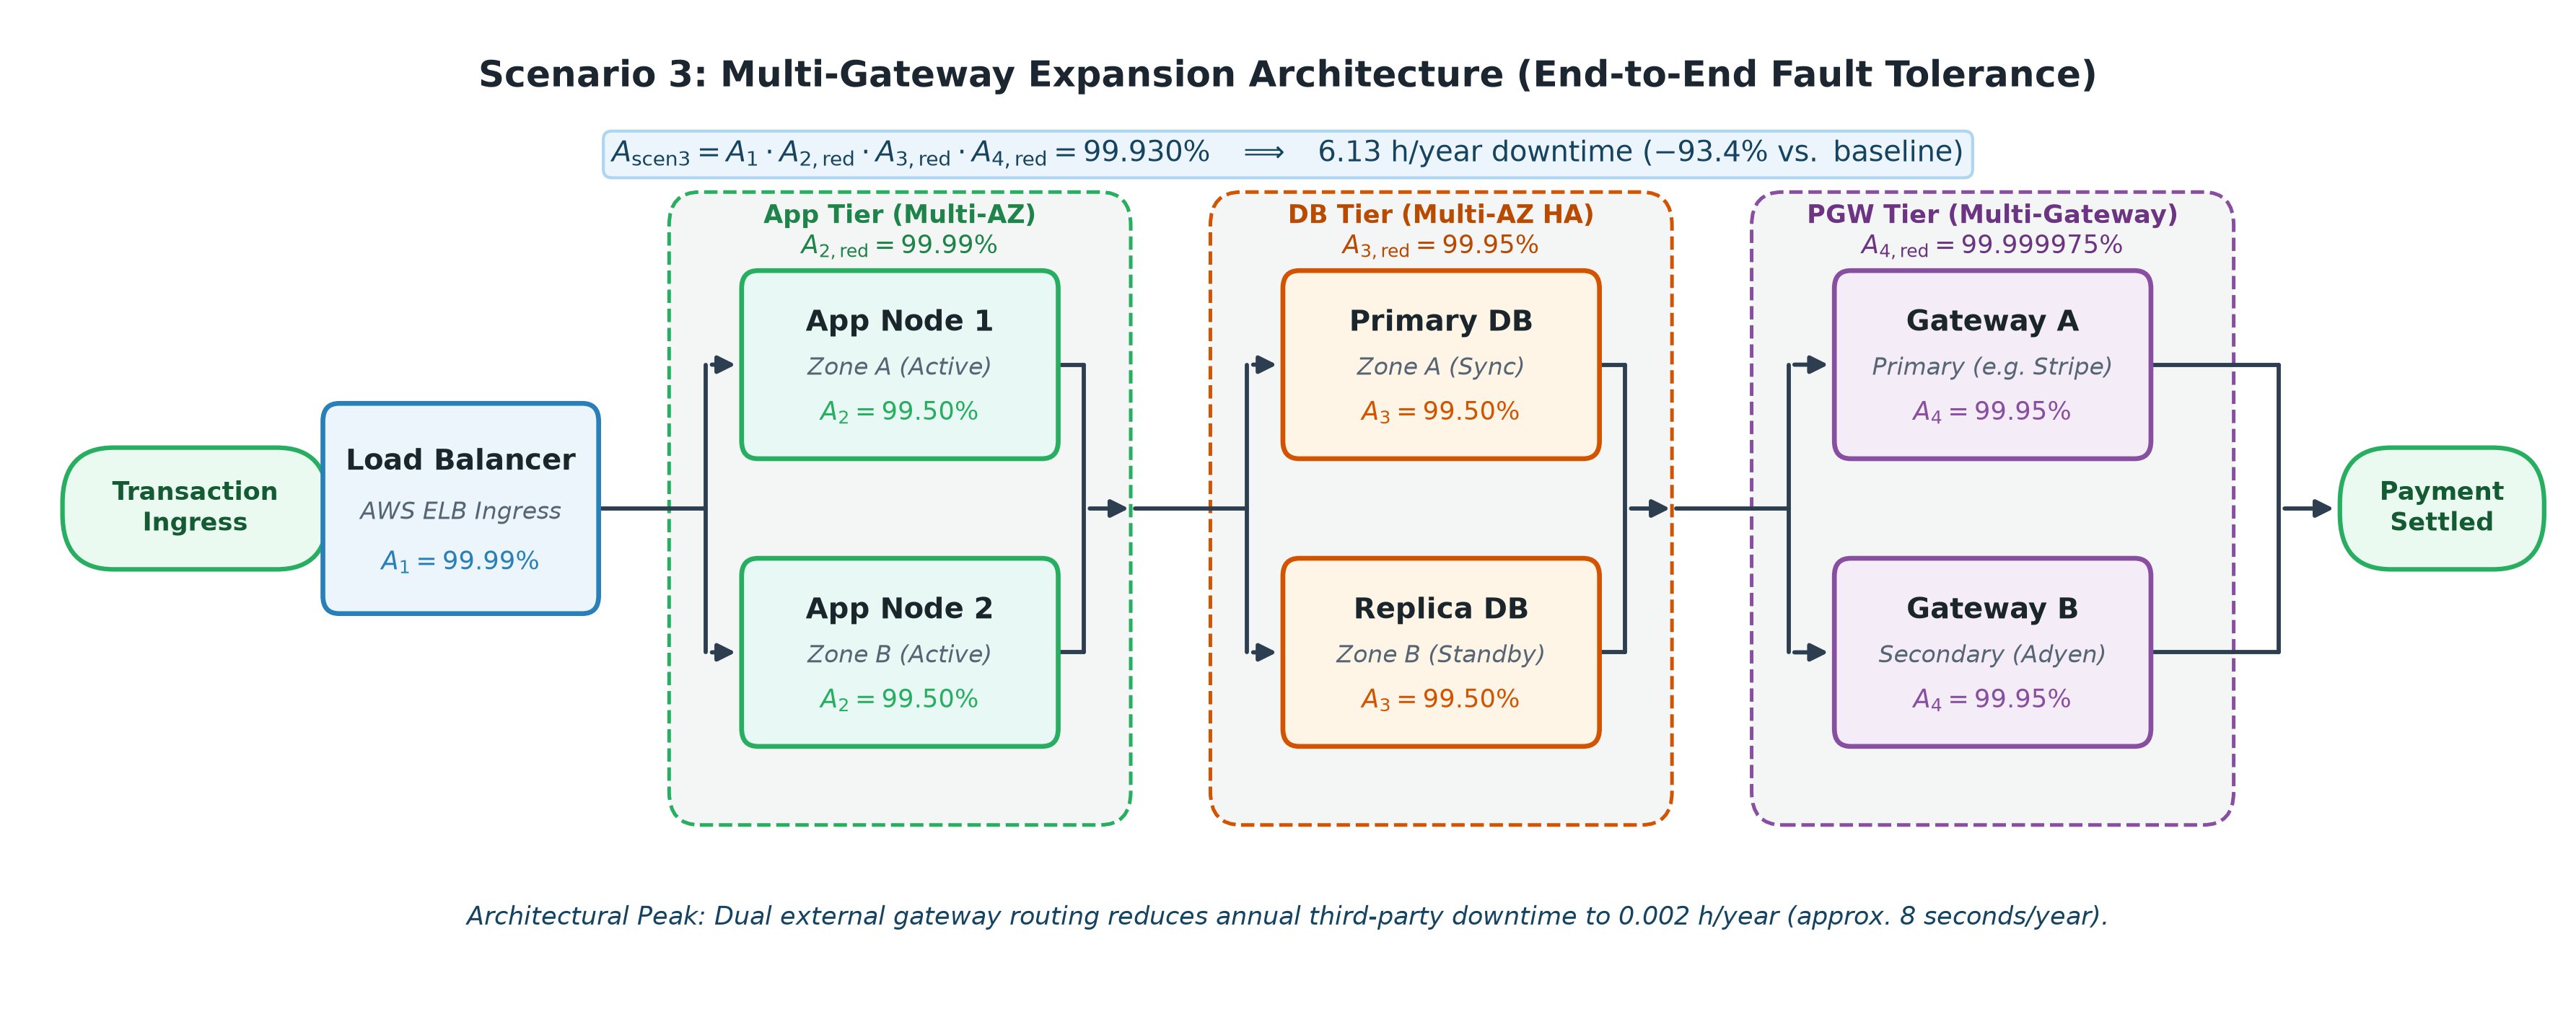

,Block,Subsystem,Tier,Operating Availability (%),Unavailability (ppm),Standalone Downtime (h/yr),Downtime (min/yr),Configuration
0,LB,Load Balancer,Ingress & Routing,99.990000,100.000000,0.876000,52.560000,Managed Multi-AZ
1,App,Application Server,Business Logic & Auth,99.990000,100.000000,0.876000,52.560000,Dual Active-Active
2,DB,Transactional Database,Data Persistence,99.950000,500.000000,4.380000,262.800000,Dual Active-Active
3,PGW,Payment Gateway,External Settlement Network,99.999975,0.250000,0.002190,0.131400,Dual Active-Active


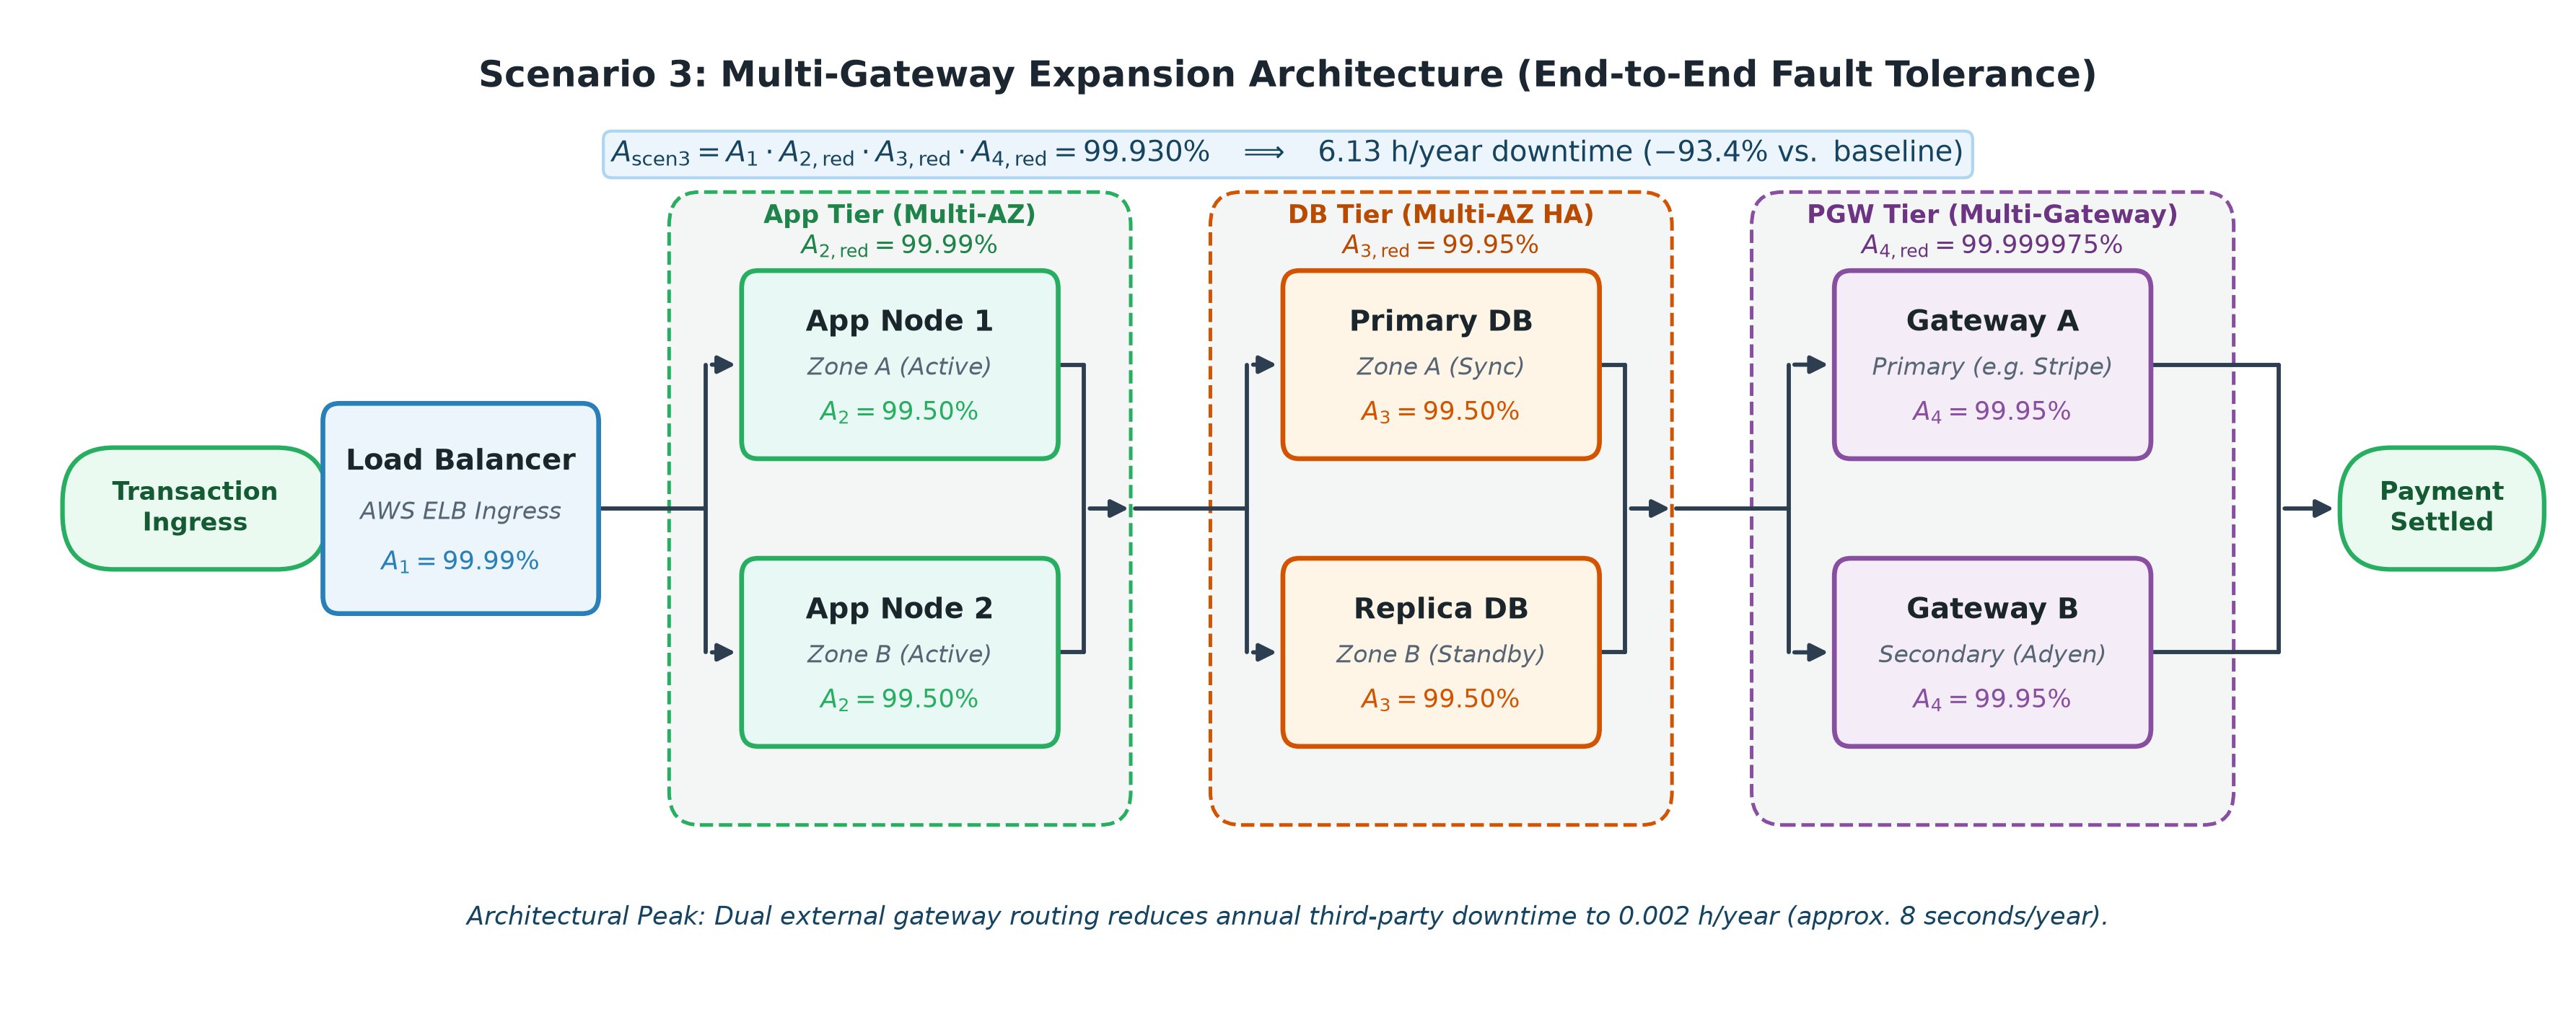

In [2]:
draw_rbd_scenario_3(output_dir=figures_dir)
img_path = figures_dir / "rbd_scenario_3.png"
if img_path.exists():
    display(Image(filename=str(img_path), width=750))

s3 = evaluate_scenario_3()
block_rows = []
for code, b in DEFAULT_BLOCKS.items():
    a_op = s3.block_availabilities[code]
    u_op = 1.0 - a_op
    d_h = u_op * HOURS_PER_YEAR
    block_rows.append({
        "Block": code,
        "Subsystem": b.name,
        "Tier": b.tier,
        "Operating Availability (%)": a_op * 100.0,
        "Unavailability (ppm)": u_op * 1e6,
        "Standalone Downtime (h/yr)": d_h,
        "Downtime (min/yr)": d_h * 60.0,
        "Configuration": "Dual Active-Active" if code in ["App", "DB", "PGW"] else "Managed Multi-AZ",
    })

df_blocks = pd.DataFrame(block_rows)
display(df_blocks)


## 2. Active Parallel Redundancy in Payment Gateways

In [3]:
a_pgw_single = DEFAULT_BLOCKS["PGW"].availability_base
u_pgw_single = 1.0 - a_pgw_single
d_single_h = u_pgw_single * HOURS_PER_YEAR

a_pgw_red = calculate_parallel_availability([a_pgw_single, a_pgw_single])
u_pgw_red = 1.0 - a_pgw_red
d_red_h = u_pgw_red * HOURS_PER_YEAR
d_red_sec = d_red_h * 3600.0

print("PAYMENT GATEWAY REDUNDANCY FORMULATION:")
print(f"\nSingle Gateway SLA Availability (A_4): {a_pgw_single:.6f} ({a_pgw_single*100:.4f}%)")
print(f"Single Gateway Unavailability (U_4): {u_pgw_single:.6f} ({u_pgw_single*1e6:.1f} ppm)")
print(f"Single Gateway Annual Downtime: {d_single_h:.4f} hours/year ({d_single_h*60:.2f} min/year)")

print(f"\nDual-Active Redundant Availability (A_4,red): {a_pgw_red:.8f} ({a_pgw_red*100:.6f}%)")
print(f"Dual-Active Unavailability (U_4,red): {u_pgw_red:.8f} ({u_pgw_red*1e6:.2f} ppm)")
print(f"Dual-Active Annual Downtime: {d_red_h:.6f} hours/year ({d_red_sec:.2f} seconds/year)")
print(f"Downtime Reduction Factor: {d_single_h / d_red_h:,.0f}x improvement")


PAYMENT GATEWAY REDUNDANCY FORMULATION:

Single Gateway SLA Availability (A_4): 0.999500 (99.9500%)
Single Gateway Unavailability (U_4): 0.000500 (500.0 ppm)
Single Gateway Annual Downtime: 4.3800 hours/year (262.80 min/year)

Dual-Active Redundant Availability (A_4,red): 0.99999975 (99.999975%)
Dual-Active Unavailability (U_4,red): 0.00000025 (0.25 ppm)
Dual-Active Annual Downtime: 0.002190 hours/year (7.88 seconds/year)
Downtime Reduction Factor: 2,000x improvement


## 3. Scenario 3 System Availability and Downtime Evaluation

In [4]:
s1 = evaluate_scenario_1()
s2 = evaluate_scenario_2()
s3 = evaluate_scenario_3()

print("SCENARIO 3 EVALUATION RESULTS:")
print(f"\nSystem Availability (A_scen3): {s3.system_availability:.10f} ({s3.system_availability*100:.4f}%)")
print(f"System Unavailability (U_scen3): {s3.unavailability:.10f} ({s3.unavailability*100:.5f}%)")
print(f"Annual Downtime: {s3.annual_downtime_hours:.4f} hours/year ({s3.annual_downtime_minutes:.2f} minutes/year)")
print(f"Downtime Saved vs Baseline (S1): {s1.annual_downtime_hours - s3.annual_downtime_hours:.4f} hours/year (-{s3.relative_reduction_vs_baseline_pct:.2f}%)")
print(f"Downtime Saved vs Multi-AZ (S2): {s2.annual_downtime_hours - s3.annual_downtime_hours:.4f} hours/year (-{((s2.annual_downtime_hours - s3.annual_downtime_hours)/s2.annual_downtime_hours)*100:.2f}%)")


SCENARIO 3 EVALUATION RESULTS:

System Availability (A_scen3): 0.9992998602 (99.9300%)
System Unavailability (U_scen3): 0.0007001398 (0.07001%)
Annual Downtime: 6.1332 hours/year (367.99 minutes/year)
Downtime Saved vs Baseline (S1): 86.4509 hours/year (-93.38%)
Downtime Saved vs Multi-AZ (S2): 4.3747 hours/year (-41.63%)


## 4. Cross-Scenario Comparative Synthesis

In [5]:
summaries = get_all_scenarios_summary()

comp_rows = []
for s in summaries:
    comp_rows.append({
        "Scenario": f"Scenario {s.scenario_id}",
        "Name": s.name,
        "Availability (%)": s.system_availability * 100.0,
        "Unavailability (ppm)": s.unavailability * 1e6,
        "Annual Downtime (h/yr)": s.annual_downtime_hours,
        "Annual Downtime (min/yr)": s.annual_downtime_minutes,
        "Downtime Saved vs S1 (h/yr)": s.absolute_reduction_hours_vs_baseline,
        "Reduction vs Baseline (%)": s.relative_reduction_vs_baseline_pct,
    })

df_comp = pd.DataFrame(comp_rows)
display(df_comp)


,Scenario,Name,Availability (%),Unavailability (ppm),Annual Downtime (h/yr),Annual Downtime (min/yr),Downtime Saved vs S1 (h/yr),Reduction vs Baseline (%)
0,Scenario 1,Scenario 1 (Baseline Series),98.943103,10568.965499,92.584138,5555.048266,0.000000,0.000000
1,Scenario 2,Scenario 2 (Multi-AZ Series-Parallel),99.880046,1199.540060,10.507971,630.478256,82.076167,88.650355
2,Scenario 3,Scenario 3 (Multi-Gateway Expansion),99.929986,700.139830,6.133225,367.993495,86.450913,93.375512


## 5. Third-Party Gateway SLA Sensitivity Analysis

In [6]:
sensitivity_grid = [0.99000, 0.99500, 0.99800, 0.99900, 0.99950, 0.99980, 0.99990, 0.99995]
df_sens = evaluate_gateway_availability_sensitivity(gateway_availabilities=sensitivity_grid)

display_sens = df_sens.copy()
display_sens.columns = [
    "Gateway SLA",
    "Gateway SLA (%)",
    "Single PGW Downtime (h)",
    "Dual PGW Downtime (h)",
    "Scenario 2 Avail (%)",
    "Scenario 2 Downtime (h)",
    "Scenario 3 Avail (%)",
    "Scenario 3 Downtime (h)",
    "Downtime Saved (h)",
    "Reduction vs S2 (%)",
    "Downtime Ratio (S2/S3)",
]
display(display_sens)


,Gateway SLA,Gateway SLA (%),Single PGW Downtime (h),Dual PGW Downtime (h),Scenario 2 Avail (%),Scenario 2 Downtime (h),Scenario 3 Avail (%),Scenario 3 Downtime (h),Downtime Saved (h),Reduction vs S2 (%),Downtime Ratio (S2/S3)
0,0.990000,99.000000,87.600000,0.876000,98.930711,93.669726,99.920018,7.006423,86.663303,92.520077,13.369122
1,0.995000,99.500000,43.800000,0.219000,99.430361,49.900381,99.927513,6.349883,43.550498,87.274880,7.858472
2,0.998000,99.800000,17.520000,0.035040,99.730151,23.638774,99.929611,6.166052,17.472722,73.915518,3.833697
3,0.999000,99.900000,8.760000,0.008760,99.830081,14.884905,99.929911,6.139790,8.745115,58.751566,2.424334
4,0.999500,99.950000,4.380000,0.002190,99.880046,10.507971,99.929986,6.133225,4.374746,41.632643,1.713286
5,0.999800,99.980000,1.752000,0.000350,99.910025,7.881810,99.930007,6.131387,1.750424,22.208396,1.285486
6,0.999900,99.990000,0.876000,0.000088,99.920018,7.006423,99.930010,6.131124,0.875299,12.492813,1.142763
7,0.999950,99.995000,0.438000,0.000022,99.925014,6.568730,99.930011,6.131058,0.437672,6.662956,1.071386


## 6. Sensitivity to Imperfect Failover Switching Coverage

In [7]:
c_grid = [0.80, 0.85, 0.90, 0.95, 0.98, 0.99, 1.00]
df_failover = evaluate_failover_coverage_sensitivity(coverage_probabilities=c_grid)

display_failover = df_failover.copy()
display_failover.columns = [
    "Switching Coverage (C)",
    "Coverage (%)",
    "Effective Gateway Avail (%)",
    "Effective PGW Downtime (h)",
    "System Availability (%)",
    "System Downtime (h)",
    "Downtime Saved vs S2 (h)",
    "Gain Retained vs Ideal S3 (%)",
]
display(display_failover)


,Switching Coverage (C),Coverage (%),Effective Gateway Avail (%),Effective PGW Downtime (h),System Availability (%),System Downtime (h),Downtime Saved vs S2 (h),Gain Retained vs Ideal S3 (%)
0,0.800000,80.000000,99.989980,0.877752,99.919998,7.008174,3.499797,80.000000
1,0.850000,85.000000,99.992479,0.658861,99.922495,6.789437,3.718534,85.000000
2,0.900000,90.000000,99.994978,0.439971,99.924992,6.570700,3.937271,90.000000
3,0.950000,95.000000,99.997476,0.221080,99.927489,6.351962,4.156009,95.000000
4,0.980000,98.000000,99.998976,0.089746,99.928987,6.220720,4.287251,98.000000
5,0.990000,99.000000,99.999475,0.045968,99.929487,6.176972,4.330999,99.000000
6,1.000000,100.000000,99.999975,0.002190,99.929986,6.133225,4.374746,100.000000


## 7. Common-Cause Failure (CCF) Risk Analysis ($\beta$-Factor Model)

In [8]:
beta_grid = [0.00, 0.01, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20]
df_ccf = evaluate_common_cause_failure_sensitivity(beta_factors=beta_grid)

display_ccf = df_ccf.copy()
display_ccf.columns = [
    "Beta Factor (β)",
    "CCF Share (%)",
    "Effective Gateway Avail (%)",
    "Effective PGW Downtime (h)",
    "System Availability (%)",
    "System Downtime (h)",
    "Gateway Share of Downtime (%)",
]
display(display_ccf)


,Beta Factor (β),CCF Share (%),Effective Gateway Avail (%),Effective PGW Downtime (h),System Availability (%),System Downtime (h),Gateway Share of Downtime (%)
0,0.000000,0.000000,99.999975,0.002190,99.929986,6.133225,0.035707
1,0.010000,1.000000,99.999475,0.045946,99.929487,6.176951,0.743837
2,0.020000,2.000000,99.998976,0.089703,99.928988,6.220677,1.442018
3,0.050000,5.000000,99.997477,0.220976,99.927490,6.351858,3.478926
4,0.080000,8.000000,99.995979,0.352254,99.925993,6.483044,5.433461
5,0.100000,10.000000,99.994980,0.439774,99.924994,6.570503,6.693155
6,0.150000,15.000000,99.992482,0.658582,99.922498,6.789158,9.700500
7,0.200000,20.000000,99.989984,0.877402,99.920002,7.007824,12.520315


## 8. Sensitivity Visualizations & Robustness Curves

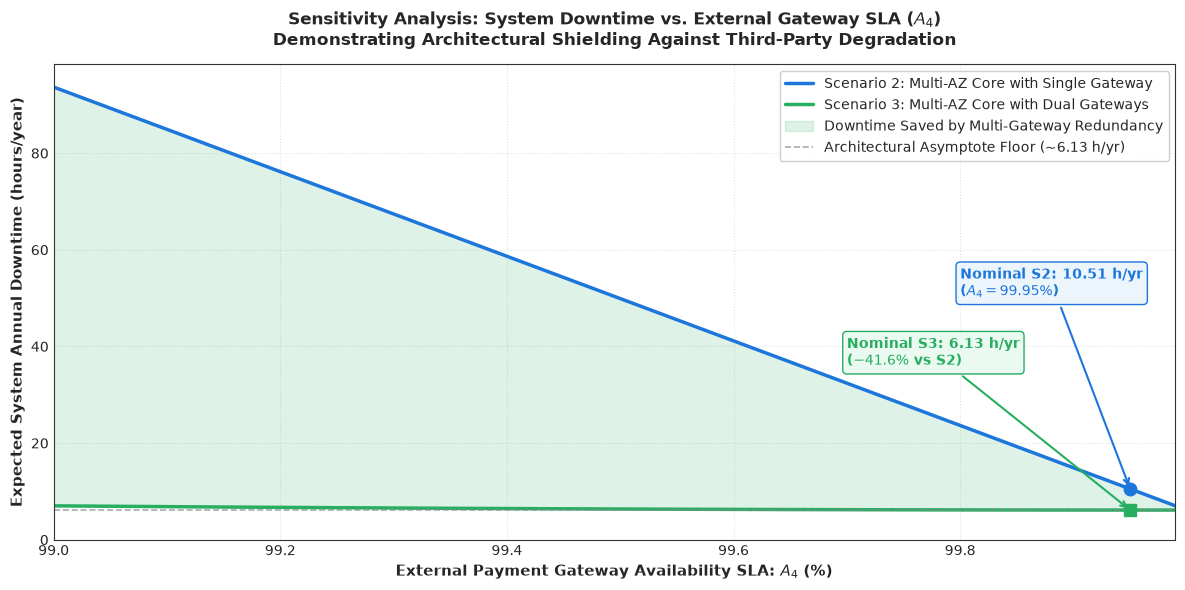

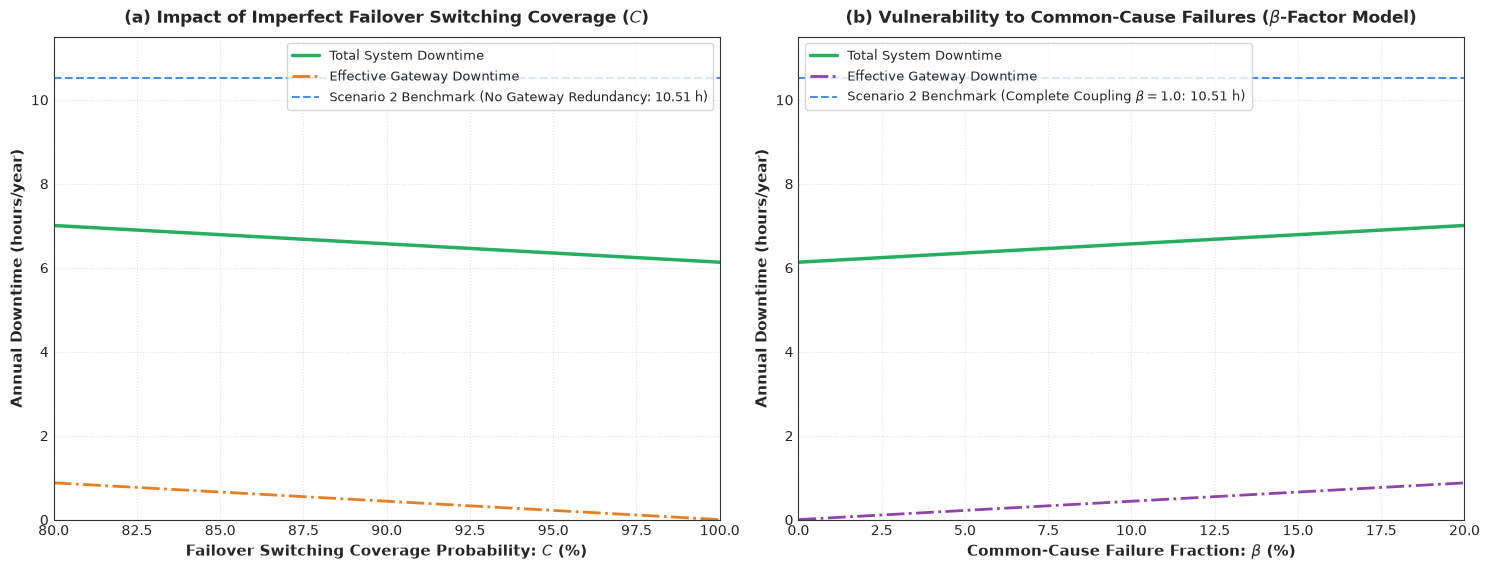

Sensitivity figures exported successfully to: /home/xavier/dev/system-reliability-engineering/reports/figures
  Verified sensitivity diagram: sensitivity_failover_and_ccf.png
  Verified sensitivity diagram: sensitivity_failover_and_ccf_sensitivity.png
  Verified sensitivity diagram: sensitivity_gateway_sla.png
  Verified sensitivity diagram: sensitivity_gateway_sla_sensitivity.png
  Verified sensitivity diagram: sensitivity_scenario_3_diminishing_returns.png


In [9]:
generate_all_sensitivity_diagrams(output_dir=figures_dir)

fig_sla = plot_gateway_sla_sensitivity(output_dir=figures_dir)
plt.show()

fig_ccf = plot_failover_and_ccf_sensitivity(output_dir=figures_dir)
plt.show()

print(f"Sensitivity figures exported successfully to: {figures_dir}")
for fpath in sorted(figures_dir.glob("sensitivity_*.png")):
    print(f"  Verified sensitivity diagram: {fpath.name}")


## 9. Architectural Bottleneck Floor and Diminishing Returns Analysis

,Step,Topology,System Availability (%),Annual Downtime (h/yr),Downtime Saved vs Previous (h/yr),Marginal Reduction (%),Cumulative Reduction vs S1 (%),Primary Bottleneck Tier
0,Baseline (Scenario 1),Pure Series (SPOF at every layer),98.943103,92.584138,0.000000,0.000000,0.000000,App & DB (94.6%)
1,Multi-AZ Core (Scenario 2),Active App Multi-AZ + DB Multi-AZ Failover,99.880046,10.507971,82.076167,88.650355,88.650355,DB & PGW (83.4%)
2,Multi-Gateway (Scenario 3),Multi-AZ Core + Dual Active-Active Gateways,99.929986,6.133225,4.374746,41.632643,93.375512,DB Failover (71.4%)
3,Global DB HA (Hypothetical S4),Multi-Gateway + Multi-Region Active-Active DB,99.978976,1.841684,4.291540,69.972006,98.010799,LB & App Ingress (95.1%)


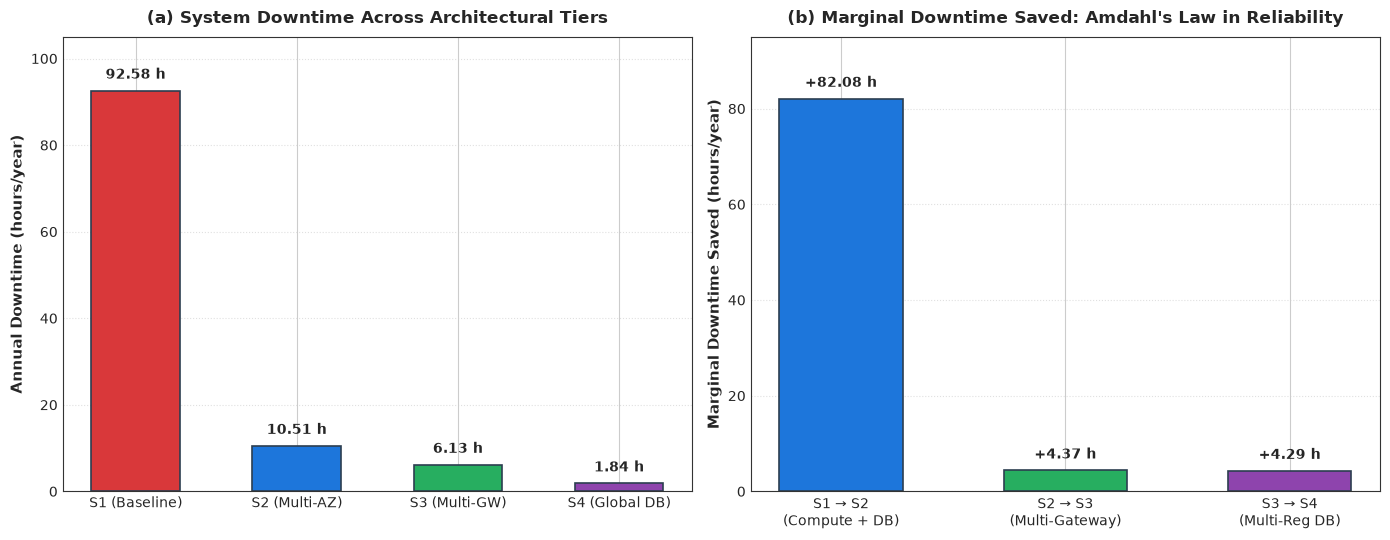

In [10]:
df_diminishing = compute_diminishing_returns_metrics()
display(df_diminishing)

fig_dim = plot_architectural_diminishing_returns(diminishing_df=df_diminishing, output_dir=figures_dir)
plt.show()
